# D1 — Global explainability: SHAP, permutation importance, ALE

Models explained: **M-LR** (C1-R logistic regression) and **M-XGB** (C1-R XGBoost, seed 0), refitted exactly as C1-R. The refit reproduces C1-R's cached test predictions, and the run aborts if it doesn't. SHAP is in log-odds: interventional TreeSHAP for XGBoost, exact linear SHAP for LR, with a shared 1,000-row training background, on 10,000 random test CVEs. Permutation importance is the PR-AUC drop on the full test set, 10 repeats. ALE is first-order, 20 quantile bins, on 20,000 test rows. Part (5) is an explanation-correctness check on **L3 (SIMULATED)**, where the true label formula is known. Design: Study D addendum (commit c0a3ee1), registered before any Study D explanation was computed.

Reads saved outputs. Run: `python -m src.explainability.shap_global` (~12 min).

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)

## Text components: what they mean (top TF-IDF terms of each SVD component)

In [2]:
pd.read_csv("outputs/d_text_component_terms.csv", index_col=0).head(25)

,terms
text_00,"candidate, reason, rejected reason, reason use..."
text_01,"remote, remote attackers, attackers, arbitrary..."
text_02,"site scripting, scripting xss, scripting, cros..."
text_03,"sql, sql injection, injection, php, arbitrary ..."
text_04,"reason cna, cna individual, requested candidat..."
text_05,"oracle, cvss, cause denial(-), denial service(..."
text_06,"servers, obtain sensitive, sensitive informati..."
text_07,"needed, execution, user, user interaction, exp..."
text_08,"sql, php(-), code(-), denial, denial service, ..."
text_09,"unspecified, users, vectors, buffer(-), overfl..."


Component 0 and several others encode **rejected / withdrawn CVE boilerplate** ("candidate … rejected reason"). They are data-quality signals, not vulnerability semantics.

## (1) SHAP: share of total mean |SHAP| by feature group, and top features

In [3]:
pd.read_csv("outputs/d1_shap_group_share.csv", index_col=0).round(3)

,M-LR,M-XGB
CVSS,0.414,0.593
EPSS,0.139,0.153
text,0.447,0.254


In [4]:
pd.read_csv("outputs/d1_shap_mean_abs.csv", index_col=0).sort_values("M-XGB", ascending=False).head(15).round(4)

,M-LR,M-XGB,label
feature,,,
cvss_version,3.3447,1.8047,cvss_version
epss_pit,0.0934,0.3873,epss_pit
cvss_score,0.3158,0.2223,cvss_score
epss_pit_pct,1.2041,0.1536,epss_pit_pct
text_10,0.1653,0.0848,"text_10 [php, cve(-), needed, windows(-), dot,..."
text_24,0.0192,0.0789,"text_24 [code execution, authenticated, execut..."
text_17,0.1726,0.0705,"text_17 [discovered, allow(-), issue, vulnerab..."
cvss_severity,0.1909,0.0644,cvss_severity
text_20,0.1662,0.0574,"text_20 [withdrawn, candidate withdrawn, withd..."


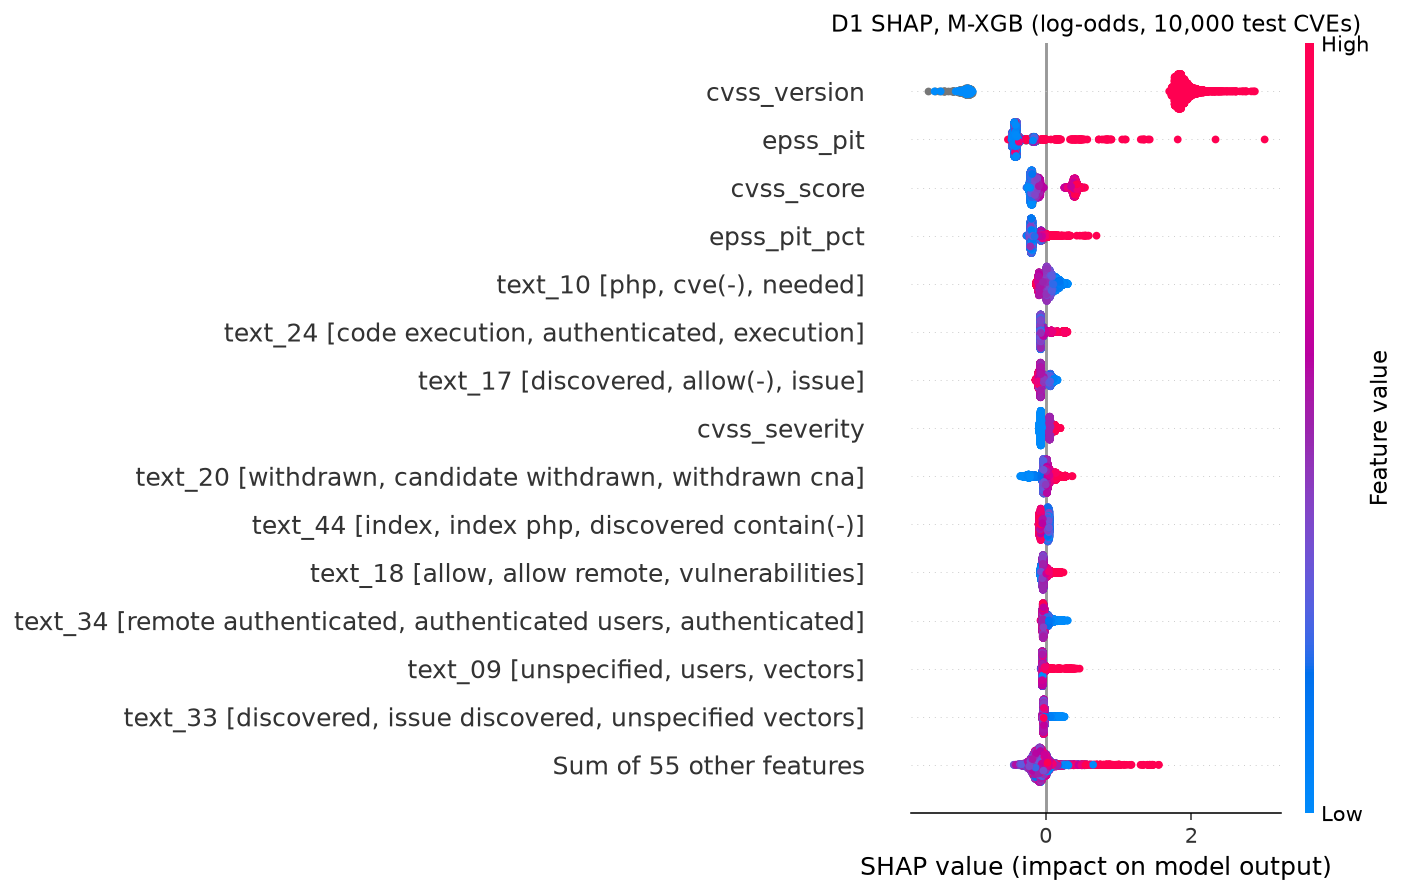

In [5]:
Image("outputs/d1_beeswarm_xgboost.png")

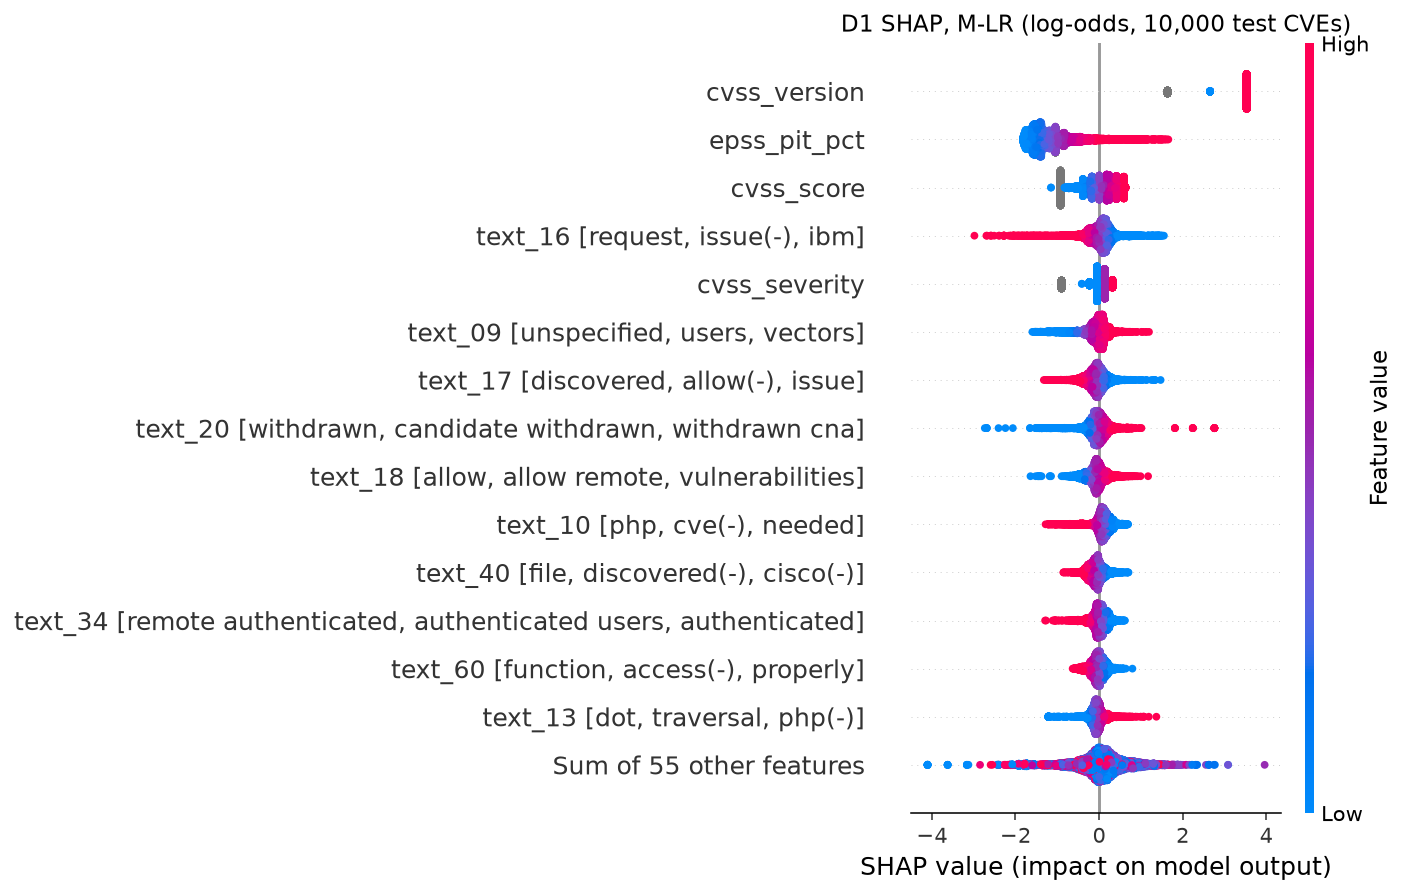

In [6]:
Image("outputs/d1_beeswarm_logreg.png")

## (2) Permutation importance (PR-AUC drop, 10 repeats, full test set)

In [7]:
p = pd.read_csv("outputs/d1_permutation_importance.csv")
p[p.unit.str.startswith("GROUP:")].round(4)

,unit,pr_auc_drop_mean,pr_auc_drop_std,model,base_pr_auc
69,GROUP:CVSS,0.0066,0.0014,M-LR,0.0235
70,GROUP:text,0.0087,0.0017,M-LR,0.0235
71,GROUP:EPSS,0.0191,0.0002,M-LR,0.0235
141,GROUP:CVSS,0.0065,0.0012,M-XGB,0.0220
142,GROUP:text,0.0046,0.0015,M-XGB,0.0220
143,GROUP:EPSS,0.0173,0.0002,M-XGB,0.0220


In [8]:
p[~p.unit.str.startswith("GROUP:")].sort_values(["model", "pr_auc_drop_mean"], ascending=[True, False]).groupby("model").head(8).round(4)

,unit,pr_auc_drop_mean,pr_auc_drop_std,model,base_pr_auc
68,epss_pit_pct,0.0168,0.0010,M-LR,0.0235
67,epss_pit,0.0118,0.0002,M-LR,0.0235
37,text_34,0.0045,0.0008,M-LR,0.0235
20,text_17,0.0042,0.0006,M-LR,0.0235
19,text_16,0.0033,0.0008,M-LR,0.0235
0,cvss_score,0.0026,0.0013,M-LR,0.0235
12,text_09,0.0019,0.0016,M-LR,0.0235
29,text_26,0.0017,0.0004,M-LR,0.0235
139,epss_pit,0.0161,0.0002,M-XGB,0.0220
140,epss_pit_pct,0.0035,0.0004,M-XGB,0.0220


## (3) Accumulated local effects

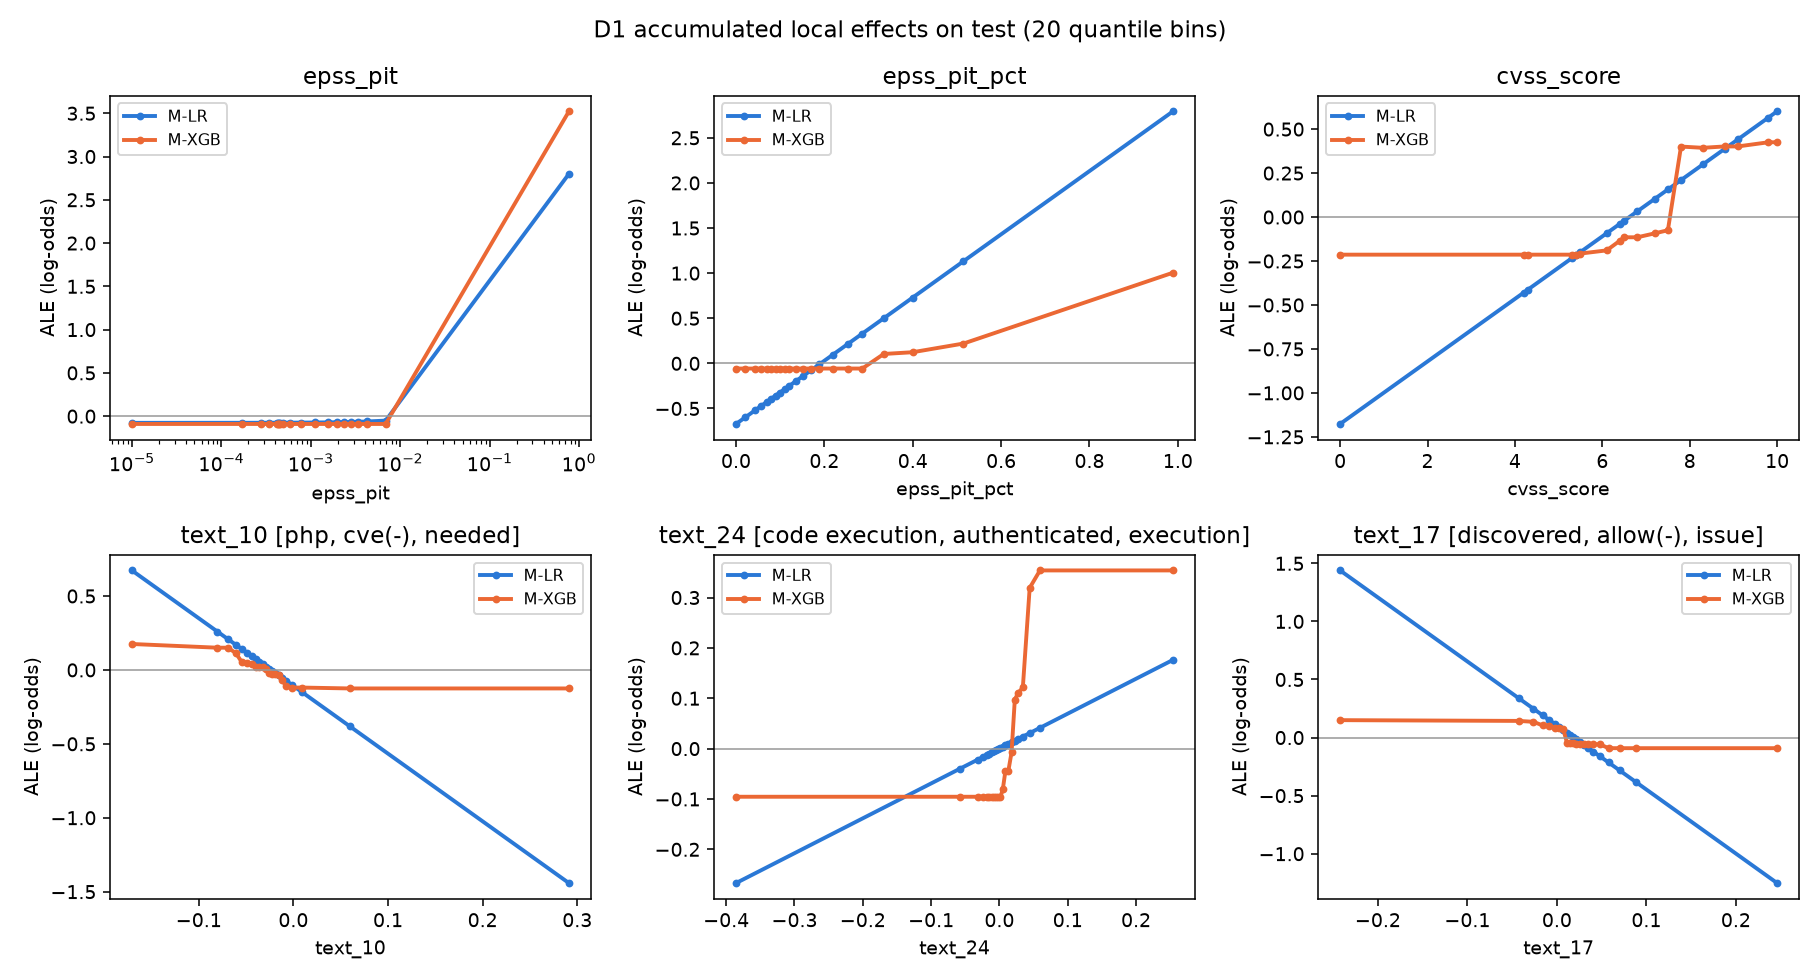

In [9]:
Image("outputs/d1_ale.png")

## (4) Do the global rankings agree? (Kendall τ-b over 69 features)

In [10]:
pd.read_csv("outputs/d1_global_ranking_agreement.csv", index_col=0).round(3)

,SHAP M-XGB,SHAP M-LR,PermImp M-XGB,PermImp M-LR
SHAP M-XGB,1.000,0.295,0.169,0.165
SHAP M-LR,0.295,1.000,0.066,0.176
PermImp M-XGB,0.169,0.066,1.000,0.293
PermImp M-LR,0.165,0.176,0.293,1.000


**Reading (L1).**
- **The two global methods tell different stories.** Permutation importance, i.e. what the model's *ranking* actually depends on, says **EPSS-PIT**: permuting the two EPSS features removes 0.017–0.019 of 0.022–0.024 PR-AUC, about 80%. CVSS removes about 0.0066, and text 0.0046 (M-XGB) to 0.0087 (M-LR); group drops are not additive. This agrees with the C4 ablation. Mean |SHAP| gives EPSS only 14–15% of attribution mass, while CVSS gets 59% (M-XGB) and text 45% (M-LR).
- **Why: `cvss_version` dominates SHAP** (M-XGB 1.80, M-LR 3.34 mean |φ|, rank 1 for both) but matters little to the ranking (permutation drop 0.002 / 0.0005). Test CVEs are 90% CVSS v3.1, while the training background is 36% v2.0. SHAP therefore attributes a large, nearly constant amount to "this is a v3 CVE", measured against a background from another era. That shifts every test CVE about equally and barely changes the order. The exploratory background check (`DX` section in D5) quantifies it.
- Rank agreement is correspondingly low: SHAP vs permutation τ ≈ 0.17 for both models. Even permutation importance agrees only τ = 0.29 across the two models, because the many weak text features rank noisily.
- **ALE:** M-XGB is flat in EPSS below about 0.008 and jumps above it, a threshold rule. M-LR is linear in the EPSS percentile, which is where its signal sits. Both rise with CVSS score; XGBoost does so in one step at about 7.5.

## (5) L3 explanation-correctness check — SIMULATED (true formula known)

In [11]:
t = pd.read_csv("outputs/d1_l3_shap_vs_formula.csv", index_col=0)
share = t.loc[t.in_formula, "mean_abs_shap"].sum() / t.mean_abs_shap.sum()
print(f"share of mean |SHAP| on features the formula uses: {share:.3f}")
t.round(4)

share of mean |SHAP| on features the formula uses: 0.861


,mean_abs_shap,in_formula,formula_importance
base_severity,2.9860,True,0.0797
sla_breached,2.3348,True,0.0253
internet_facing,2.1421,True,0.0126
regulatory_scope,2.0762,True,0.0383
criticality_tier,1.5998,True,0.0153
public_exploit,1.2966,True,0.0090
epss_score,1.0551,False,0.0000
recurrence_count,0.8517,True,0.0032
epss_percentile,0.5066,True,0.0301
tool,0.3519,False,0.0000


**Reading (L3, simulated).** The model fits the formula almost perfectly (held-out PR-AUC 0.9995). SHAP puts 86% of its mass on features the formula really uses, and its importance ranking agrees with the formula's own term importance at τ = 0.61. Two errors are instructive:
- **`epss_score` (not in the formula) gets about twice the attribution of `epss_percentile` (in the formula).** The two are almost perfectly rank-correlated, and SHAP credits whichever one the trees happened to split on. **SHAP explains the model, not the data-generating process.**
- The scale of SHAP's attributions does not track the formula's weights: `sla_breached` and `internet_facing` rank above `epss_percentile`. This is because SHAP measures effect on the log-odds of crossing a threshold, not the linear score.

An analyst reading SHAP here would get the right *set* of drivers, attribute one of them to the wrong correlated proxy, and weight them differently from the true rule.